# AICE Professional 주피터라이트 실전 모의고사 14회 — 군 PBL 수행평가 재구성(군 차량 반복사고 · LENS-ON 질의 의도 · Q-GUARD 도면 유형)

## [ 필독 ] AICE Professional 모의고사 유의사항

- 공식 샘플문항(가공식품 카테고리 분류)과 **같은 시험지 형식**으로 만든 모의고사입니다. 3문항, 180분 기준입니다.
- 공식 시험과 같은 **Tabular / Text / Image 3유형**입니다. 2번 Text 문항은 공식 샘플(상품명 → 카테고리)과 같은 텍스트 분류입니다.
- 본인 스스로 모델을 만들고 **달성 목표 이상의 성능**이 나오도록 개발해야 합니다. 정답(테스트 라벨)은 제공되지 않습니다.
  대신 이 노트북 **맨 마지막 셀**(전체 자동 채점, 정답 키 인코딩)로 제출 파일을 스스로 채점할 수 있습니다(연습용).

## 사용할 수 있는 라이브러리 (주피터라이트 판)

이 모의고사는 **브라우저 주피터라이트(Pyodide · Python 3.14)** 에서 설치 없이 끝까지 풀 수 있도록 라이브러리를 제한했습니다.
필요한 라이브러리는 주피터라이트에 **미리 설치**되어 있습니다. 맨 위 '브라우저 실습' 셀은 확인만 하고 바로 끝납니다(Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다).

| 구분 | 쓸 수 있음 | 쓰지 않음(브라우저에서 안 됨) |
|---|---|---|
| 데이터·그림 | numpy · pandas · matplotlib · seaborn · Pillow | — |
| 머신러닝 | scikit-learn · LightGBM · XGBoost · imbalanced-learn · joblib | CatBoost |
| 텍스트 | scikit-learn 의 CountVectorizer · TfidfVectorizer · 내장 영어 불용어, **NLTK**(불용어·토큰화·어간 추출, 데이터는 `/drive/nltk_data` 에 미리 들어 있음) | 형태소 분석기 · BERT 등 사전학습 언어 모델 |
| 딥러닝 | `tensorflow.keras` 문법(TensorFlow.js 로 실행되는 대체 구현체, 미리 설치): `Sequential`·함수형(`Input` → 층 → `Model`) · Dense · Dropout · BatchNormalization · Conv2D · MaxPooling2D · GlobalAveragePooling2D · Embedding · LSTM · GRU · 콜백 3종(EarlyStopping · ModelCheckpoint · ReduceLROnPlateau) · `load_img` · `img_to_array` · `image_dataset_from_directory` · `ImageDataGenerator` · `model.save` / `load_model` · **MobileNet v1 전이학습**(`alpha=0.25`, 224×224, `weights='imagenet'` 만) | PyTorch · 다른 사전학습 모델(MobileNetV2/V3 · ResNet · EfficientNet 등) · 사용자 정의 층·손실 · GPU |

- 이미지는 64×64 정도로 줄여 작은 CNN 을 직접 학습하거나, MobileNet v1(alpha 0.25)로 특징을 뽑아 분류기를 학습하세요(전이학습). 브라우저 TensorFlow.js 는 CPython TensorFlow 와 수치가 조금 달라 딥러닝 점수가 약간 다르게 나올 수 있습니다.
- 학습이 오래 걸리면 epoch 를 줄이거나 조기 종료(EarlyStopping)를 쓰세요. 최신 Chrome·Edge 를 권장합니다.

## 시간 배분(180분)

| 문항 | 권장 시간 | 먼저 할 일 |
|---|---|---|
| 1. Tabular (30점) | 50분 | `info()`·`describe()` 로 자료형·결측 확인 → 기본 모델로 제출 파일부터 만들기 |
| 2. Text (35점) | 60분 | 라벨 분포·문장 길이 확인 → TF-IDF + 선형 모델로 기준 점수 |
| 3. Image (35점) | 60분 | 압축 풀기·폴더 구조 확인 → 작은 CNN 으로 기준 점수 |
| 마무리 | 10분 | 제출 파일 6개 이름·열 구조 확인 → 맨 마지막 채점 셀 실행 |

## 시험 자원 가이드

| 구분 | 공식 시험 | 이 모의고사 |
|---|---|---|
| IDE | CPU 8 core · Memory 32G · GPU 1개(VRAM 16GB) | **브라우저 주피터라이트**(설치 없음, CPU) — Colab·로컬 Jupyter 에서도 그대로 실행됨 |
| SW | Python 3.10 · TensorFlow 2.13 · PyTorch 2.1 | Python 3.14(Pyodide) · scikit-learn · LightGBM · XGBoost · Keras 문법(TensorFlow.js) — 위 표의 라이브러리만 |

## 유의 사항

- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 제출 파일명은 **고정**입니다: `answer_1~3` 모델 파일과 `answer_1~3.csv`.


문제에 제시되는 가이드는 필수적으로 준수하여 주시기 바랍니다. 이를 준수하지 않을 경우 채점 제한 또는 0점 처리될 수 있으니
각별히 유의해 주시기 바랍니다.

#### **[학습 정보]**
- 학습 목표 : Tabular · Text · Image 예측 모델 3종을 만들어 달성 목표 이상의 예측 파일을 제출하고, 제출한 코드로 같은 모델이 재현되게 할 수 있다
- AICE 역량 : PT1·PT2 표 데이터 / PX1·PX2 텍스트 / PI1·PI2 이미지 / PS1 제출 파일 형식·재현성
- 제출 파일 : `answer_1~3` 모델 파일(.pkl · .h5 등)과 `answer_1~3.csv` — **파일명은 고정**입니다(이름을 바꾸면 채점되지 않음)

| 문항 | 문제 | 달성 목표 | 역량 | 기술 | 예상 시간 |
|---|---|---|---|---|---|
| 1. Tabular | 군 차량 사고의 반복사고 여부 예측 | F1-score 0.62 이상 | PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | pandas, scikit-learn(ColumnTransformer, Pipeline, OneHotEncoder, StandardScaler, TfidfVectorizer, LogisticRegression), joblib | 50분 |
| 2. Text | LENS-ON 군수 질의 문장의 의도 분류(6종) | 정확도 0.9 이상 | PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | pandas, scikit-learn(Pipeline, TfidfVectorizer, MultinomialNB, LinearSVC, StratifiedKFold), joblib | 60분 |
| 3. Image | 도면 이미지로 도면 유형 분류(6종) | 정확도 0.9 이상 | PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | pandas, Keras(TensorFlow.js) | 60분 |

In [1]:
# (브라우저 실습) 주피터라이트에는 tensorflow(TensorFlow.js 대체 구현체)·scikit-learn·LightGBM 등이 미리 설치되어 있어 이 셀은 확인만 합니다.
# Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다.
import os, sys, importlib.util
if 'pyodide' in sys.modules:
    os.environ['AICE_IMG_DIR'] = '/tmp/aice_images/' + os.path.basename(os.getcwd())   # 이미지 압축은 메모리 폴더에 풂(빠름)
    if not ('tensorflow' in sys.modules or importlib.util.find_spec('tensorflow')):
        # 미리 설치되지 않은 사이트(패치 전 주피터라이트)에서만: 같은 폴더의 tfjs_keras.py 를 불러옵니다
        sys.path[:0] = [os.getcwd(), '/drive']
        import tfjs_keras
        await tfjs_keras.load()
print('준비 완료 — 다음 셀로 넘어가세요.')

준비 완료 — 다음 셀로 넘어가세요.


## 1. Tabular 문제 - 군 차량 사고의 반복사고 여부 예측 (30점)

<sub>학습 목표: 군 차량 사고의 반복사고 여부 예측 모델로 테스트 F1-score 0.62 이상을 달성할 수 있다 | 역량: PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | 기술: pandas, scikit-learn(ColumnTransformer, Pipeline, OneHotEncoder, StandardScaler, TfidfVectorizer, LogisticRegression), joblib | 난이도: 실전 | 예상 시간: 50분</sub>

### 문제 개요

군 차량 사고 한 건이 **반복 사고**(같은 부대에서 비슷한 사고가 되풀이된 것, 1)인지 예측하는 이진 분류 문제입니다. 반복 사고는 '같은 부대·같은 지역·같은 유형' 사고가 최근에 있었는지와 깊이 관련되어 있어, **날짜순 이전 기록으로 파생 변수**를 만드는 것이 핵심입니다.

제공된 훈련 데이터셋을 활용해 이진 분류 모델을 개발하고, 테스트 데이터셋의 '반복사고여부' 값을 예측하시기 바랍니다.

### 달성 목표

"01_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **F1-score 0.62 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `01_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `01_test_x.csv`: 테스트 데이터셋입니다. 라벨('반복사고여부') 값이 제외되어 있습니다.

**Label 정보**

- '반복사고여부' : 1 = 반복 사고, 0 = 아님 (약 30%)

**Data 정보**

- 'id · 사고번호 · 사고발생일' : 행 번호 · 사고 번호 · 날짜(YYYY-MM-DD)
- '부대코드 · 지역코드' : A~J부대 · 지역1~8
- '차량유형 · 차량연식 · 운전자경력연수' : 세단·트럭·버스·특수차량·오토바이 · 년 · 년
- '기상상태 · 시간대' : 맑음·비·눈·빙판·안개 · 주간/야간
- '사고유형 · 사고등급' : 추돌·부주의·과속·후진사고·빙판길미끄러짐·기타 · 경미/중대/인명피해
- '수리비용 · 손해율퍼센트 · 정비이력건수' : 원 · % · 건
- '사고보고서_요약' : 사고 경위 문장

**데이터 출처** — 제7회 데이터한마당 본선 1팀(Command Compass AI) 차량안전 데이터 형식으로 다시 합성(훈련용, 실제 부대 자료 아님) — 사고 3,200건

### 데이터 예시

`01_train.csv`

| id | 사고번호 | 사고발생일 | 부대코드 | 지역코드 | 차량유형 | 차량연식 | 운전자경력연수 | … |
|---|---|---|---|---|---|---|---|---|
| 1 | ACC-00910 | 2023-10-31 | C부대 | 지역3 | 특수차량 | 2 | 8.7 | … |
| 2 | ACC-01154 | 2024-01-24 | B부대 | 지역8 | 세단 | 15 | 4.2 | … |
| 3 | ACC-02080 | 2024-12-13 | B부대 | 지역4 | 특수차량 | 9 | 12.3 | … |

`01_test_x.csv`

| id | 사고번호 | 사고발생일 | 부대코드 | 지역코드 | 차량유형 | 차량연식 | 운전자경력연수 | … |
|---|---|---|---|---|---|---|---|---|
| 1 | ACC-03098 | 2025-11-27 | I부대 | 지역1 | 특수차량 | 15 | 6.1 | … |
| 2 | ACC-00106 | 2023-02-03 | D부대 | 지역6 | 트럭 | 13 | 4.6 | … |
| 3 | ACC-02931 | 2025-10-01 | J부대 | 지역8 | 세단 | 4 | 5.1 | … |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 군 차량 사고의 반복사고 여부 예측 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_1.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('반복사고여부') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_1.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 '반복사고여부' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 '반복사고여부' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- train·test_x 를 **합쳐 날짜순으로 정렬**한 뒤 같은 부대·지역·사고유형의 **직전 사고와의 간격(일)** 을 만들어 보세요(정답 열은 쓰지 않음).
- 사고보고서_요약 글에도 단서가 있습니다. 숫자·범주 컬럼과 함께 `ColumnTransformer` 로 TF-IDF 를 붙일 수 있습니다.
- 평가 지표는 **F1-score(반복=1 기준)** 입니다. 분류 임계값을 교차검증으로 고르면 점수가 크게 오릅니다. 예측값은 0/1 정수로 제출하세요.

### 채점 진행 방식 안내

- 1번 문항 배점 : 30점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_1.csv 로 제출된 예측 데이터를 정답지와 대조하여, **F1-score 0.558 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [2]:

# 1. 라이브러리 및 데이터 불러오기
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

train_file_1 = next(
    (f for f in ["01_train(1).csv", "01_train.csv"] if Path(f).exists()),
    None
)
test_file_1 = next(
    (f for f in ["01_test_x(2).csv", "01_test_x.csv"] if Path(f).exists()),
    None
)

if train_file_1 is None or test_file_1 is None:
    raise FileNotFoundError("14회차 1번 CSV 파일 2개를 업로드해 주세요.")

train_1 = pd.read_csv(train_file_1)
test_1 = pd.read_csv(test_file_1)

assert train_1.shape == (2400, 17), "14회차 훈련 파일을 확인하세요."
assert test_1.shape == (800, 16), "14회차 테스트 파일을 확인하세요."

# 2. 훈련·테스트 데이터를 합쳐 날짜순 정렬
all_1 = pd.concat(
    [train_1.drop(columns=["반복사고여부"]), test_1],
    ignore_index=True
)

all_1["사고발생일"] = pd.to_datetime(all_1["사고발생일"])
all_1["_row"] = np.arange(len(all_1))

all_1 = all_1.sort_values(
    ["사고발생일", "사고번호"],
    kind="stable"
)

# 3. 이전 사고 관련 파생변수 생성
group_cols_1 = ["부대코드", "지역코드", "사고유형"]

all_1["동일조건_과거사고횟수"] = (
    all_1.groupby(group_cols_1).cumcount()
)

previous_date_1 = (
    all_1.groupby(group_cols_1)["사고발생일"].shift()
)

all_1["동일조건_직전사고간격일"] = (
    (all_1["사고발생일"] - previous_date_1)
    .dt.days.fillna(-1)
)

all_1["최근90일_동일조건사고"] = (
    all_1["동일조건_직전사고간격일"]
    .between(0, 90)
    .astype(int)
)

# 4. 날짜 파생변수 생성
all_1["연도"] = all_1["사고발생일"].dt.year
all_1["월"] = all_1["사고발생일"].dt.month
all_1["요일"] = all_1["사고발생일"].dt.dayofweek

# 5. 원래 행 순서 복원 및 입력 변수 생성
all_1 = all_1.sort_values("_row")

X_all_1 = all_1.drop(
    columns=["_row", "id", "사고번호", "사고발생일"]
)

X_1 = X_all_1.iloc[:len(train_1)].copy()
X_test_1 = X_all_1.iloc[len(train_1):].copy()
y_1 = train_1["반복사고여부"]

# 6. 학습·검증 분리
X_train_1, X_valid_1, y_train_1, y_valid_1 = train_test_split(
    X_1, y_1,
    test_size=0.2,
    stratify=y_1,
    random_state=42
)

# 7. 데이터 확인
print("훈련 원본:", train_1.shape)
print("테스트 원본:", test_1.shape)
print("학습용:", X_train_1.shape)
print("검증용:", X_valid_1.shape)

print("\n정답 분포:")
print(y_1.value_counts())
print("반복사고 비율:", round(y_1.mean() * 100, 2), "%")

print("\n결측값:")
print(X_1.isna().sum()[lambda x: x > 0])

print("\n입력 변수:")
print(X_1.columns.tolist())

print("\n최근 90일 사고 여부별 정답 분포:")
print(pd.crosstab(
    X_1["최근90일_동일조건사고"],
    y_1
))


훈련 원본: (2400, 17)
테스트 원본: (800, 16)
학습용: (1920, 19)
검증용: (480, 19)

정답 분포:
반복사고여부
0    1628
1     772
Name: count, dtype: int64
반복사고 비율: 32.17 %

결측값:
Series([], dtype: int64)

입력 변수:
['부대코드', '지역코드', '차량유형', '차량연식', '운전자경력연수', '기상상태', '시간대', '사고유형', '사고등급', '수리비용', '정비이력건수', '손해율퍼센트', '사고보고서_요약', '동일조건_과거사고횟수', '동일조건_직전사고간격일', '최근90일_동일조건사고', '연도', '월', '요일']

최근 90일 사고 여부별 정답 분포:
반복사고여부           0    1
최근90일_동일조건사고           
0             1149  190
1              479  582


In [3]:

# 1. 라이브러리 불러오기
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score
import numpy as np

# 2. 입력 변수 유형 구분
categorical_1 = [
    "부대코드", "지역코드", "차량유형", "기상상태",
    "시간대", "사고유형", "사고등급"
]
text_col_1 = "사고보고서_요약"
numeric_1 = [
    col for col in X_1.columns
    if col not in categorical_1 + [text_col_1]
]

# 3. 전처리 구성
preprocessor_1 = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_1),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_1),
    ("text", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 4),
        min_df=2,
        max_features=6000
    ), text_col_1)
])

# 4. 분류 모델 생성
model_1 = Pipeline([
    ("preprocessor", preprocessor_1),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        C=1.0,
        max_iter=3000,
        solver="liblinear",
        random_state=42
    ))
])

# 5. 3-Fold 교차검증으로 임계값 선택
cv_1 = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)

cv_proba_1 = cross_val_predict(
    model_1, X_train_1, y_train_1,
    cv=cv_1, method="predict_proba"
)[:, 1]

thresholds_1 = np.round(np.arange(0.25, 0.76, 0.05), 2)

cv_scores_1 = [
    f1_score(y_train_1, (cv_proba_1 >= t).astype(int))
    for t in thresholds_1
]

best_threshold_1 = float(thresholds_1[np.argmax(cv_scores_1)])

# 6. 학습 데이터로 모델 학습
model_1.fit(X_train_1, y_train_1)

# 7. 독립 검증 데이터 평가
valid_proba_1 = model_1.predict_proba(X_valid_1)[:, 1]
pred_valid_1 = (valid_proba_1 >= best_threshold_1).astype(int)

f1_1 = f1_score(y_valid_1, pred_valid_1)

print("최적 임계값:", best_threshold_1)
print(f"교차검증 F1: {max(cv_scores_1):.4f}")
print(f"검증 F1: {f1_1:.4f}")
print(f"Precision: {precision_score(y_valid_1, pred_valid_1):.4f}")
print(f"Recall: {recall_score(y_valid_1, pred_valid_1):.4f}")
print("목표 F1: 0.6200")
print(f"목표 달성: {'성공' if f1_1 >= 0.62 else '미달성'}")


최적 임계값: 0.5
교차검증 F1: 0.6427
검증 F1: 0.6607
Precision: 0.6099
Recall: 0.7208
목표 F1: 0.6200
목표 달성: 성공


In [4]:

# 1. 라이브러리 불러오기
from sklearn.base import clone
import joblib
import os

# 2. 기존 모델 설정으로 최종 모델 생성
final_model_1 = clone(model_1)

# 3. 전체 훈련 데이터로 재학습
final_model_1.fit(X_1, y_1)

# 4. 최종 모델 저장
joblib.dump(final_model_1, "answer_1.pkl")

# 5. 저장 결과 확인
print("최종 학습 데이터:", X_1.shape)
print("최종 모델:", type(final_model_1.named_steps["classifier"]).__name__)
print("분류 클래스:", final_model_1.classes_.tolist())
print("최종 임계값:", best_threshold_1)
print("모델 파일:", "answer_1.pkl")
print("파일 크기:",
      round(os.path.getsize("answer_1.pkl") / 1024, 2), "KB")
print("모델 저장 완료")


최종 학습 데이터: (2400, 19)
최종 모델: LogisticRegression
분류 클래스: [0, 1]
최종 임계값: 0.5
모델 파일: answer_1.pkl
파일 크기: 32.69 KB
모델 저장 완료


In [5]:

# 1. 라이브러리 불러오기
import joblib
import numpy as np
import pandas as pd
import os

# 2. 저장된 모델 불러오기
loaded_model_1 = joblib.load("answer_1.pkl")

# 3. 저장 전후 예측 확률 비교
proba_before_1 = final_model_1.predict_proba(X_test_1)[:, 1]
proba_after_1 = loaded_model_1.predict_proba(X_test_1)[:, 1]

np.testing.assert_allclose(
    proba_before_1, proba_after_1,
    rtol=1e-12, atol=1e-12
)
print("모델 복원 및 예측값 일치: PASS")

# 4. 최적 임계값으로 테스트 예측
pred_test_1 = (
    proba_after_1 >= best_threshold_1
).astype(int)

# 5. 원본 테스트 데이터에 정답 컬럼 추가
answer_1 = test_1.copy()
answer_1["반복사고여부"] = pred_test_1

# 6. 제출 CSV 저장
answer_1.to_csv("answer_1.csv", index=False)

# 7. 저장된 CSV 다시 읽어 검증
check_1 = pd.read_csv("answer_1.csv")

assert os.path.exists("answer_1.pkl")
assert len(check_1) == len(test_1) == 800
assert check_1.columns.tolist() == (
    test_1.columns.tolist() + ["반복사고여부"]
)

pd.testing.assert_frame_equal(
    check_1.drop(columns=["반복사고여부"]),
    test_1
)

assert check_1["반복사고여부"].notna().all()
assert check_1["반복사고여부"].isin([0, 1]).all()
assert np.array_equal(
    check_1["반복사고여부"].to_numpy(),
    pred_test_1
)

# 8. 최종 결과 확인
print("제출 파일 검증: PASS")
print("CSV 크기:", check_1.shape)
print("정답 컬럼:", check_1.columns[-1])

print("\n예측 클래스별 개수:")
print(check_1["반복사고여부"].value_counts())

print("\n예측 결과 미리보기:")
print(check_1[["id", "반복사고여부"]].head())

print("\n제출 파일: answer_1.pkl, answer_1.csv")


모델 복원 및 예측값 일치: PASS
제출 파일 검증: PASS
CSV 크기: (800, 17)
정답 컬럼: 반복사고여부

예측 클래스별 개수:
반복사고여부
0    455
1    345
Name: count, dtype: int64

예측 결과 미리보기:
   id  반복사고여부
0   1       1
1   2       0
2   3       0
3   4       1
4   5       0

제출 파일: answer_1.pkl, answer_1.csv


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

자료형·결측·양성(1) 비율부터 확인합니다. 번호·날짜 원문·정답과 같은 정보(누수) 열은 빼고, 범주형은 원-핫 인코딩합니다. '참고'의 파생 변수를 만든 뒤 후보 모델 두세 개를 **교차검증 F1** 로 비교하고, 양성이 적으면 **분류 임계값**도 교차검증으로 고르세요.

- 이 문항의 핵심: train·test_x 를 **합쳐 날짜순으로 정렬**한 뒤 같은 부대·지역·사고유형의 **직전 사고와의 간격(일)** 을 만들어 보세요(정답 열은 쓰지 않음).

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pandas`, `joblib`, `ColumnTransformer`, `Pipeline`, `OneHotEncoder`, `StandardScaler`, `TfidfVectorizer`, `LogisticRegression`, `StratifiedKFold`, `cross_val_predict`, `f1_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.compose import ____
from sklearn.pipeline import ____
from sklearn.preprocessing import ____, ____
from sklearn.feature_extraction.text import ____
from sklearn.linear_model import ____
from sklearn.model_selection import ____, ____
from sklearn.metrics import ____

train = pd.read_csv('01_train.csv')
test = pd.read_csv('01_test_x.csv')
LABEL = '____'
print(train.shape, test.shape, '____', round(train[LABEL].mean(), ____))

# train·test 를 합쳐 날짜순으로: 같은 부대·지역·유형의 직전 사고와의 간격(정답은 쓰지 않음)

# ▷ 후보 모델을 교차검증으로 비교(점수 출력)
# ▷ 분류 임계값을 교차검증으로 고르기
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_1.pkl`(모델) · `answer_1.csv`(예측)

</details>

## 2. Text 문제 - LENS-ON 군수 질의 문장의 의도 분류(6종) (35점)

<sub>학습 목표: LENS-ON 군수 질의 문장의 의도 분류(6종) 모델로 테스트 정확도 0.9 이상을 달성할 수 있다 | 역량: PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | 기술: pandas, scikit-learn(Pipeline, TfidfVectorizer, MultinomialNB, LinearSVC, StratifiedKFold), joblib | 난이도: 중급 | 예상 시간: 60분</sub>

### 문제 개요

사용자가 입력한 군수 질의 문장을 **의도 6종**(재산현황·현황비교·소요판단·가동률·정비현황·보급요청)으로 분류해 해당 화면으로 바로 연결하는 문제입니다. 띄어쓰기 없이 쓰거나 글자를 빠뜨린 질의, 아주 짧은 질의가 섞여 있어 **글자 조각(char n-gram)** 이 단어 단위보다 강합니다.

제공된 훈련 데이터셋을 활용해 텍스트 다중 분류(6종) 모델을 개발하고, 테스트 데이터셋의 '질의유형' 값을 예측하시기 바랍니다.

### 달성 목표

"02_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 90% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `02_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `02_test_x.csv`: 테스트 데이터셋입니다. 라벨('질의유형') 값이 제외되어 있습니다.

**Label 정보**

- '질의유형' : 재산현황 / 현황비교 / 소요판단 / 가동률 / 정비현황 / 보급요청

**Data 정보**

- 'id' : 행 번호
- '부대코드' : 부대A~C
- '질의내용' : 사용자 질의 문장

**데이터 출처** — 제7회 데이터한마당 본선 18팀(LENS-ON) 군수질의 데이터 형식으로 다시 합성(훈련용, 실제 부대 자료 아님) — 질의 3,600건

### 데이터 예시

`02_train.csv`

| id | 부대코드 | 질의내용 | 질의유형 |
|---|---|---|---|
| 1 | 부대B | 장갑차 부품 대기 정 건수 | 정비현황 |
| 2 | 부대C | 부대C 자주포 가동 | 가동률 |
| 3 | 부대B | 대B 구급차 정비 대기 몇 대 | 정비현황 |

`02_test_x.csv`

| id | 부대코드 | 질의내용 |
|---|---|---|
| 1 | 부대B | 전차 정비 완료 예정일 |
| 2 | 부대B | 부대A보유통신장비수량 |
| 3 | 부대A | 부대C 정비고 입고 전차 목록 |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 LENS-ON 군수 질의 문장의 의도 분류(6종) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_2.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('질의유형') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_2.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 '질의유형' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 '질의유형' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- `TfidfVectorizer(analyzer='char_wb', ngram_range=(1, 3))` 처럼 글자 조각을 쓰면 띄어쓰기 실수에 강해집니다. 단어 단위와 비교해 보세요.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트 행 순서(`id`)를 유지하고 의도 이름을 그대로 제출하세요.

### 채점 진행 방식 안내

- 2번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_2.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 81% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [7]:

# 1. 라이브러리 및 데이터 불러오기
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

train_file_2 = next(
    (f for f in ["02_train(1).csv", "02_train.csv"] if Path(f).exists()),
    None
)
test_file_2 = next(
    (f for f in ["02_test_x(1).csv", "02_test_x.csv"] if Path(f).exists()),
    None
)

if train_file_2 is None or test_file_2 is None:
    raise FileNotFoundError("14회차 2번 CSV 파일을 업로드해 주세요.")

train_2 = pd.read_csv(train_file_2)
test_2 = pd.read_csv(test_file_2)

assert train_2.shape == (2880, 4), "14회차 훈련 파일을 확인하세요."
assert test_2.shape == (720, 3), "14회차 테스트 파일을 확인하세요."

# 2. 텍스트 전처리
def preprocess_text_2(df):
    return (
        df["질의내용"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

X_2 = preprocess_text_2(train_2)
y_2 = train_2["질의유형"]
X_test_2 = preprocess_text_2(test_2)

# 3. 학습·검증 데이터 분리
X_train_2, X_valid_2, y_train_2, y_valid_2 = train_test_split(
    X_2, y_2,
    test_size=0.2,
    stratify=y_2,
    random_state=42
)

# 4. 데이터 확인
print("훈련 원본:", train_2.shape)
print("테스트 원본:", test_2.shape)
print("학습용:", X_train_2.shape)
print("검증용:", X_valid_2.shape)

print("\n클래스별 개수:")
print(y_2.value_counts())

print("\n결측값 개수:")
print(train_2.isna().sum())

print("\n평균 문장 길이:", round(X_2.str.len().mean(), 1))
print("최소 문장 길이:", X_2.str.len().min())
print("최대 문장 길이:", X_2.str.len().max())

print("\n전처리 결과 예시:")
print(X_2.head(5).to_string(index=False))


훈련 원본: (2880, 4)
테스트 원본: (720, 3)
학습용: (2304,)
검증용: (576,)

클래스별 개수:
질의유형
소요판단    487
재산현황    485
정비현황    482
현황비교    478
보급요청    478
가동률     470
Name: count, dtype: int64

결측값 개수:
id      0
부대코드    0
질의내용    0
질의유형    0
dtype: int64

평균 문장 길이: 12.3
최소 문장 길이: 4
최대 문장 길이: 23

전처리 결과 예시:
  장갑차 부품 대기 정 건수
      부대C 자주포 가동
대B 구급차 정비 대기 몇 대
   부대C 보유 발전기 수량
         통신장비수량요


In [8]:

# 1. 라이브러리 불러오기
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# 2. TF-IDF + LinearSVC 모델 생성
model_2 = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(2, 5),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# 3. 모델 학습
model_2.fit(X_train_2, y_train_2)

# 4. 검증 데이터 예측
pred_valid_2 = model_2.predict(X_valid_2)

# 5. 정확도 평가
accuracy_2 = accuracy_score(y_valid_2, pred_valid_2)

print(f"검증 Accuracy: {accuracy_2:.4f}")
print(f"검증 정확도: {accuracy_2 * 100:.2f}%")
print("목표 정확도: 90.00%")
print(f"목표 달성: {'성공' if accuracy_2 >= 0.90 else '미달성'}")

print("\n클래스별 성능:")
print(classification_report(y_valid_2, pred_valid_2))

print("\nTF-IDF 특징 개수:")
print(len(model_2.named_steps["tfidf"].vocabulary_))


검증 Accuracy: 0.9462
검증 정확도: 94.62%
목표 정확도: 90.00%
목표 달성: 성공

클래스별 성능:
              precision    recall  f1-score   support

         가동률       0.94      0.97      0.95        94
        보급요청       0.96      0.94      0.95        96
        소요판단       0.98      0.92      0.95        97
        재산현황       0.96      0.95      0.95        97
        정비현황       0.92      0.93      0.92        96
        현황비교       0.93      0.98      0.95        96

    accuracy                           0.95       576
   macro avg       0.95      0.95      0.95       576
weighted avg       0.95      0.95      0.95       576


TF-IDF 특징 개수:
4478


In [9]:

# 1. 라이브러리 불러오기
from sklearn.base import clone
import joblib
import os

# 2. 기존 모델 설정 복사
final_model_2 = clone(model_2)

# 3. 전체 훈련 데이터로 재학습
final_model_2.fit(X_2, y_2)

# 4. 모델 저장
joblib.dump(final_model_2, "answer_2.pkl")

# 5. 저장 결과 확인
print("최종 학습 데이터:", X_2.shape)
print("분류 클래스:", final_model_2.classes_.tolist())
print("TF-IDF 특징 개수:",
      len(final_model_2.named_steps["tfidf"].vocabulary_))
print("모델 파일:", "answer_2.pkl")
print("파일 크기:",
      round(os.path.getsize("answer_2.pkl") / 1024, 2), "KB")
print("모델 저장 완료")


최종 학습 데이터: (2880,)
분류 클래스: ['가동률', '보급요청', '소요판단', '재산현황', '정비현황', '현황비교']
TF-IDF 특징 개수: 5109
모델 파일: answer_2.pkl
파일 크기: 358.18 KB
모델 저장 완료


In [10]:

# 1. 라이브러리 불러오기
import joblib
import numpy as np
import pandas as pd
import os

# 2. 저장된 모델 불러오기
loaded_model_2 = joblib.load("answer_2.pkl")

# 3. 저장 전후 예측 결과 비교
pred_before_2 = final_model_2.predict(X_test_2)
pred_after_2 = loaded_model_2.predict(X_test_2)

assert np.array_equal(pred_before_2, pred_after_2)
print("모델 복원 및 예측값 일치: PASS")

# 4. 원본 테스트 데이터에 정답 컬럼 추가
answer_2 = test_2.copy()
answer_2["질의유형"] = pred_after_2

# 5. 제출 CSV 저장
answer_2.to_csv("answer_2.csv", index=False)

# 6. 저장된 CSV 다시 읽어 검증
check_2 = pd.read_csv("answer_2.csv")

assert os.path.exists("answer_2.pkl")
assert len(check_2) == len(test_2) == 720
assert check_2.columns.tolist() == test_2.columns.tolist() + ["질의유형"]

pd.testing.assert_frame_equal(
    check_2.drop(columns=["질의유형"]),
    test_2
)

assert check_2["질의유형"].notna().all()
assert check_2["질의유형"].isin(loaded_model_2.classes_).all()
assert np.array_equal(
    check_2["질의유형"].to_numpy(),
    pred_after_2
)

# 7. 최종 결과 확인
print("제출 파일 검증: PASS")
print("CSV 크기:", check_2.shape)
print("정답 컬럼:", check_2.columns[-1])

print("\n예측 클래스별 개수:")
print(check_2["질의유형"].value_counts())

print("\n예측 결과 미리보기:")
print(check_2[["id", "질의유형"]].head())

print("\n제출 파일: answer_2.pkl, answer_2.csv")


모델 복원 및 예측값 일치: PASS
제출 파일 검증: PASS
CSV 크기: (720, 4)
정답 컬럼: 질의유형

예측 클래스별 개수:
질의유형
정비현황    128
현황비교    121
소요판단    120
보급요청    120
가동률     116
재산현황    115
Name: count, dtype: int64

예측 결과 미리보기:
   id  질의유형
0   1  정비현황
1   2  재산현황
2   3  정비현황
3   4  정비현황
4   5  보급요청

제출 파일: answer_2.pkl, answer_2.csv


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

라벨 분포와 문장 길이를 확인합니다. 문장을 TF-IDF 로 바꾸되 **단어 단위와 글자 조각(char n-gram)** 을 비교하고, 나이브 베이즈·선형 SVM·로지스틱 회귀 중 **교차검증 정확도** 가 높은 조합으로 전체 학습하세요. 다른 컬럼(숫자·범주)이 단서이면 `ColumnTransformer` 로 함께 넣습니다.

- 이 문항의 핵심: `TfidfVectorizer(analyzer='char_wb', ngram_range=(1, 3))` 처럼 글자 조각을 쓰면 띄어쓰기 실수에 강해집니다. 단어 단위와 비교해 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pandas`, `joblib`, `Pipeline`, `TfidfVectorizer`, `MultinomialNB`, `LinearSVC`, `StratifiedKFold`, `cross_val_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.pipeline import ____
from sklearn.feature_extraction.text import ____
from sklearn.naive_bayes import ____
from sklearn.svm import ____
from sklearn.model_selection import ____, ____

train = pd.read_csv('02_train.csv')

# ▷ 후보 모델을 교차검증으로 비교(점수 출력)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_2.pkl`(모델) · `answer_2.csv`(예측)

</details>

## 3. Image 문제 - 도면 이미지로 도면 유형 분류(6종) (35점)

<sub>학습 목표: 도면 이미지로 도면 유형 분류(6종) 모델로 테스트 정확도 0.9 이상을 달성할 수 있다 | 역량: PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | 기술: pandas, Keras(TensorFlow.js) | 난이도: 중급 | 예상 시간: 60분</sub>

### 문제 개요

품질검사 담당자가 올린 **도면 이미지**를 6유형(부품도·조립도·배치도·전개도·배관도·배선도)으로 분류해 같은 유형의 기준 도면을 찾아 주는 문제입니다(VRAG 검색의 첫 단계). 도면이 90° 단위로 돌아가 있거나 스캔 잡음·표제란이 섞여 있습니다.

제공된 훈련 데이터셋을 활용해 이미지 다중 분류(6종) 모델을 개발하고, 테스트 데이터셋의 'label' 값을 예측하시기 바랍니다.

### 달성 목표

"03_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 90% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `03_images.zip`: 압축을 풀면 `03_train/<클래스>/dwg_*.png`(학습)와 `03_test/test_*.png`(테스트) 폴더가 생깁니다. 64×64 컬러 PNG.
- `03_train.csv`: 학습 이미지 파일명과 라벨
- `03_test_x.csv`: 테스트 이미지 파일명(라벨 제외)

**Label 정보**

- 'label' : assembly: 조립도 / layout: 배치도 / part: 부품도 / piping: 배관도 / unfolded: 전개도 / wiring: 배선도

**데이터 출처** — 제7회 데이터한마당 본선 3팀(Q-GUARD 도면 판독 품질검사) 도면유형으로 합성한 도면 이미지(훈련용) — 6유형 × 300장

### 데이터 예시

학습 이미지 라벨별 장수: unfolded 240, layout 240, part 240, assembly 240, piping 240, wiring 240

| file_name | label |
|---|---|
| dwg_00001.png | unfolded |
| dwg_00002.png | layout |
| dwg_00003.png | part |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 도면 이미지로 도면 유형 분류(6종) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_3.h5** (또는 다른 확장자의 모델 파일)

(2) 라벨('label') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_3.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'label' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'label' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 도면은 돌리거나 뒤집어도 같은 유형이라 회전·뒤집기 증강이 잘 맞습니다.
- 작은 CNN(`Sequential` + `Conv2D`)을 직접 학습합니다. 1/255 로 나눠 0~1 로 맞추고, Dropout·조기 종료로 과적합을 막으세요.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트는 `03_test_x.csv` 의 파일명 순서대로 읽어 예측하세요.

### 채점 진행 방식 안내

- 3번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_3.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 81% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

훈련 원본: (1440, 64, 64, 3)
테스트 이미지: 360
학습용: (1152, 64, 64, 3)
검증용: (288, 64, 64, 3)

클래스별 개수:
label
unfolded    240
layout      240
part        240
assembly    240
piping      240
wiring      240
Name: count, dtype: int64

클래스 매핑:
{'assembly': 0, 'layout': 1, 'part': 2, 'piping': 3, 'unfolded': 4, 'wiring': 5}

픽셀 범위: 0.0 ~ 1.0
누락 이미지: 0

첫 번째 도면 이미지:


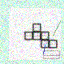

In [13]:

# 1. 라이브러리 불러오기
import zipfile
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split

# 2. 14회차 파일 경로 설정
zip_file_3 = "03_images.zip"
train_file_3 = "03_train.csv"
test_file_3 = "03_test_x.csv"
image_dir_3 = Path("aice14_images")

# 3. 이미지 압축 해제
if not (image_dir_3 / "03_train").is_dir() or not (image_dir_3 / "03_test").is_dir():
    image_dir_3.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_file_3, "r") as z:
        z.extractall(image_dir_3)

# 4. 학습 및 테스트 CSV 불러오기
train_3 = pd.read_csv(train_file_3)
test_3 = pd.read_csv(test_file_3)

assert train_3.shape == (1440, 2)
assert test_3.shape == (360, 1)

# 5. 이미지 경로 생성
train_paths_3 = [
    image_dir_3 / "03_train" / label / name
    for name, label in zip(train_3["file_name"], train_3["label"])
]

test_paths_3 = [
    image_dir_3 / "03_test" / name
    for name in test_3["file_name"]
]

missing_train_3 = sum(not p.exists() for p in train_paths_3)
missing_test_3 = sum(not p.exists() for p in test_paths_3)

assert missing_train_3 == 0
assert missing_test_3 == 0

# 6. 이미지 불러오기 및 정규화
def load_image_3(path):
    with Image.open(path) as img:
        img = img.convert("RGB").resize((64, 64))
        return np.asarray(img, dtype=np.float32) / 255.0

X_3 = np.stack([
    load_image_3(path) for path in train_paths_3
])

# 7. 정답 라벨 숫자 변환
classes_3 = sorted(train_3["label"].unique())
class_to_idx_3 = {
    label: idx for idx, label in enumerate(classes_3)
}

y_3 = train_3["label"].map(class_to_idx_3).to_numpy()

# 8. 학습·검증 데이터 분리
X_train_3, X_valid_3, y_train_3, y_valid_3 = train_test_split(
    X_3, y_3,
    test_size=0.2,
    stratify=y_3,
    random_state=42
)

# 9. 결과 확인
print("훈련 원본:", X_3.shape)
print("테스트 이미지:", len(test_paths_3))
print("학습용:", X_train_3.shape)
print("검증용:", X_valid_3.shape)

print("\n클래스별 개수:")
print(train_3["label"].value_counts())

print("\n클래스 매핑:")
print(class_to_idx_3)

print("\n픽셀 범위:", X_3.min(), "~", X_3.max())
print("누락 이미지:", missing_train_3 + missing_test_3)

print("\n첫 번째 도면 이미지:")
display(Image.open(train_paths_3[0]))


In [14]:

# 1. 라이브러리 불러오기
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, classification_report

tf.random.set_seed(42)
np.random.seed(42)

# 2. 흑백 변환 및 명암 반전
def preprocess_image_3(images):
    gray = images.mean(axis=-1, keepdims=True)
    return (1.0 - gray).astype(np.float32)

X_train_gray_3 = preprocess_image_3(X_train_3)
X_valid_gray_3 = preprocess_image_3(X_valid_3)

# 3. 90도 단위 회전 증강
X_aug_3 = np.concatenate([
    np.rot90(X_train_gray_3, k=k, axes=(1, 2))
    for k in range(4)
]).copy()

y_aug_3 = np.tile(y_train_3, 4)

# 4. CNN 모델 구성
model_3 = Sequential([
    Input(shape=(64, 64, 1)),

    Conv2D(32, 3, activation="relu", padding="same"),
    MaxPooling2D(2),

    Conv2D(64, 3, activation="relu", padding="same"),
    MaxPooling2D(2),

    Conv2D(128, 3, activation="relu", padding="same"),
    MaxPooling2D(2),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(6, activation="softmax")
])

# 5. 모델 컴파일
model_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. 조기 종료 설정
callbacks_3 = [
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=8,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.00001
    )
]

# 7. 모델 학습
history_3 = model_3.fit(
    X_aug_3,
    y_aug_3,
    validation_data=(X_valid_gray_3, y_valid_3),
    epochs=35,
    batch_size=64,
    callbacks=callbacks_3,
    verbose=1
)

# 8. 검증 정확도 평가
valid_proba_3 = model_3.predict(X_valid_gray_3, verbose=0)
pred_valid_3 = np.argmax(valid_proba_3, axis=1)

accuracy_3 = accuracy_score(y_valid_3, pred_valid_3)

print("\n증강 후 학습 데이터:", X_aug_3.shape)
print("실제 학습 Epoch:", len(history_3.history["loss"]))
print(f"검증 Accuracy: {accuracy_3:.4f}")
print(f"검증 정확도: {accuracy_3 * 100:.2f}%")
print("목표 정확도: 90.00%")
print(f"목표 달성: {'성공' if accuracy_3 >= 0.90 else '미달성'}")

print("\n클래스별 성능:")
print(classification_report(
    y_valid_3,
    pred_valid_3,
    target_names=classes_3
))


Epoch 1/35
72/72 ━━━━━━━━━━━━━━━━━━━━ 44s 581ms/step - accuracy: 0.3817 - loss: 1.4841 - val_accuracy: 0.5417 - val_loss: 1.1041 - learning_rate: 0.0010
Epoch 2/35
72/72 ━━━━━━━━━━━━━━━━━━━━ 82s 586ms/step - accuracy: 0.6873 - loss: 0.8436 - val_accuracy: 0.8125 - val_loss: 0.5773 - learning_rate: 0.0010
Epoch 3/35
72/72 ━━━━━━━━━━━━━━━━━━━━ 42s 590ms/step - accuracy: 0.8181 - loss: 0.5018 - val_accuracy: 0.8889 - val_loss: 0.3459 - learning_rate: 0.0010
Epoch 4/35
72/72 ━━━━━━━━━━━━━━━━━━━━ 81s 579ms/step - accuracy: 0.8702 - loss: 0.3699 - val_accuracy: 0.8924 - val_loss: 0.3394 - learning_rate: 0.0010
Epoch 5/35
72/72 ━━━━━━━━━━━━━━━━━━━━ 42s 581ms/step - accuracy: 0.9138 - loss: 0.2570 - val_accuracy: 0.9167 - val_loss: 0.2583 - learning_rate: 0.0010
Epoch 6/35
72/72 ━━━━━━━━━━━━━━━━━━━━ 82s 581ms/step - accuracy: 0.9362 - loss: 0.1861 - val_accuracy: 0.8993 - val_loss: 0.3343 - learning_rate: 0.0010
Epoch 7/35
72/72 ━━━━━━━━━━━━━━━━━━━━ 42s 578ms/step - accuracy: 0.9451 - loss: 0.

In [15]:

# 1. 라이브러리 불러오기
import numpy as np
import tensorflow as tf
import os

# 2. 최고 검증 정확도를 기록한 Epoch 확인
best_epoch_3 = int(
    np.argmax(history_3.history["val_accuracy"]) + 1
)

print("최적 Epoch:", best_epoch_3)

# 3. 전체 이미지 전처리 및 회전 증강
X_full_gray_3 = preprocess_image_3(X_3)

X_full_aug_3 = np.concatenate([
    np.rot90(X_full_gray_3, k=k, axes=(1, 2))
    for k in range(4)
]).copy()

y_full_aug_3 = np.tile(y_3, 4)

# 4. 기존 CNN 구조 복사 및 새 모델 생성
tf.keras.utils.set_random_seed(42)

final_model_3 = tf.keras.models.clone_model(model_3)

final_model_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. 전체 훈련 데이터로 최종 학습
final_history_3 = final_model_3.fit(
    X_full_aug_3,
    y_full_aug_3,
    epochs=best_epoch_3,
    batch_size=64,
    verbose=1
)

# 6. 최종 모델 저장
final_model_3.save("answer_3.h5")

# 7. 저장 결과 확인
print("\n최종 훈련 이미지:", len(X_3))
print("증강 후 데이터:", X_full_aug_3.shape)
print("최종 학습 Epoch:", len(final_history_3.history["loss"]))
print("모델 파일:", "answer_3.h5")
print("파일 크기:",
      round(os.path.getsize("answer_3.h5") / 1024 / 1024, 2), "MB")
print("모델 저장 완료")


최적 Epoch: 15
Epoch 1/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 59s 597ms/step - accuracy: 0.4118 - loss: 1.4059
Epoch 2/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 49s 547ms/step - accuracy: 0.7370 - loss: 0.7077
Epoch 3/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 84s 570ms/step - accuracy: 0.8356 - loss: 0.4606
Epoch 4/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 49s 546ms/step - accuracy: 0.8899 - loss: 0.3080
Epoch 5/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 83s 560ms/step - accuracy: 0.9174 - loss: 0.2331
Epoch 6/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 49s 545ms/step - accuracy: 0.9408 - loss: 0.1720
Epoch 7/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 51s 565ms/step - accuracy: 0.9526 - loss: 0.1381
Epoch 8/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 49s 544ms/step - accuracy: 0.9526 - loss: 0.1351
Epoch 9/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 50s 562ms/step - accuracy: 0.9632 - loss: 0.1195
Epoch 10/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 82s 557ms/step - accuracy: 0.9707 - loss: 0.0873
Epoch 11/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 80s 542ms/step - accuracy: 0.9783 - loss: 0.0693
Epoch 12/15
90/90 ━━━━━━━━━━


최종 훈련 이미지: 1440
증강 후 데이터: (5760, 64, 64, 1)
최종 학습 Epoch: 15
모델 파일: answer_3.h5
파일 크기: 13.12 MB
모델 저장 완료


In [16]:

# 1. 라이브러리 불러오기
import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow.keras.models import load_model

# 2. 저장된 CNN 모델 불러오기
loaded_model_3 = load_model("answer_3.h5", compile=False)

# 3. 테스트 이미지 불러오기 및 전처리
X_test_3 = np.stack([
    load_image_3(path) for path in test_paths_3
])

X_test_gray_3 = preprocess_image_3(X_test_3)

# 4. 저장 전후 예측 결과 비교
proba_before_3 = final_model_3.predict(
    X_test_gray_3, batch_size=64, verbose=0
)

proba_after_3 = loaded_model_3.predict(
    X_test_gray_3, batch_size=64, verbose=0
)

np.testing.assert_allclose(
    proba_before_3,
    proba_after_3,
    rtol=1e-5,
    atol=1e-6
)

print("모델 복원 및 예측값 일치: PASS")

# 5. 예측값을 도면 클래스 이름으로 변환
pred_idx_3 = np.argmax(proba_after_3, axis=1)
pred_labels_3 = np.array(classes_3)[pred_idx_3]

# 6. 원본 테스트 데이터에 정답 컬럼 추가
answer_3 = test_3.copy()
answer_3["label"] = pred_labels_3

# 7. 제출 CSV 저장
answer_3.to_csv("answer_3.csv", index=False)

# 8. 저장된 CSV 다시 읽어 검증
check_3 = pd.read_csv("answer_3.csv")

assert Path("answer_3.h5").is_file()
assert Path("answer_3.csv").is_file()
assert len(check_3) == len(test_3) == 360
assert check_3.columns.tolist() == ["file_name", "label"]

pd.testing.assert_frame_equal(
    check_3.drop(columns=["label"]),
    test_3
)

assert check_3["label"].notna().all()
assert check_3["label"].isin(classes_3).all()
assert np.array_equal(
    check_3["label"].to_numpy(),
    pred_labels_3
)

# 9. 최종 결과 확인
print("제출 파일 검증: PASS")
print("CSV 크기:", check_3.shape)
print("정답 컬럼:", check_3.columns[-1])

print("\n예측 클래스별 개수:")
print(check_3["label"].value_counts())

print("\n예측 결과 미리보기:")
print(check_3.head())

print("\n제출 파일: answer_3.h5, answer_3.csv")


모델 복원 및 예측값 일치: PASS
제출 파일 검증: PASS
CSV 크기: (360, 2)
정답 컬럼: label

예측 클래스별 개수:
label
layout      62
piping      61
wiring      61
unfolded    61
part        60
assembly    55
Name: count, dtype: int64

예측 결과 미리보기:
       file_name     label
0  test_0001.png      part
1  test_0002.png    piping
2  test_0003.png  unfolded
3  test_0004.png    piping
4  test_0005.png  unfolded

제출 파일: answer_3.h5, answer_3.csv


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

압축을 풀고 폴더 구조(학습: 클래스별 폴더, 테스트: 한 폴더)를 확인합니다. 이미지를 같은 크기로 읽어 0~1 로 맞추고, 검증 데이터를 떼어 **작은 CNN**(또는 사전학습 모델 특징 + 분류기)을 학습합니다. 증강·Dropout·조기 종료로 과적합을 막고, 테스트는 `03_test_x.csv` 순서대로 예측하세요.

- 이 문항의 핵심: 도면은 돌리거나 뒤집어도 같은 유형이라 회전·뒤집기 증강이 잘 맞습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `tensorflow`, `pandas`, `train_test_split`, `load_img`, `img_to_array`, `Sequential`, `load_model`, `Input`, `Conv2D`, `MaxPooling2D`, `Flatten`, `Dense`, `Dropout`, `EarlyStopping`.

- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>
- 참고 문서: <https://keras.io/api/data_loading/image/#loadimg-function>
- 참고 문서: <https://keras.io/api/data_loading/image/#imgtoarray-function>
- 참고 문서: <https://keras.io/api/models/sequential/>
- 참고 문서: <https://keras.io/api/layers/convolution_layers/convolution2d/>
- 참고 문서: <https://keras.io/api/layers/pooling_layers/max_pooling2d/>

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
IMG_DIR = os.environ.get('____', '____')        # 압축을 풀 위치(브라우저판은 메모리 폴더 /tmp)
if not os.path.exists(os.path.join(IMG_DIR, '____')):
    zipfile.ZipFile('03_images.zip').extractall(IMG_DIR)
import ____
from sklearn.model_selection import ____
from tensorflow.keras.utils import ____, ____
from tensorflow.keras.models import ____, ____
from tensorflow.keras.layers import ____, ____, ____, ____, ____, ____
from tensorflow.keras.callbacks import ____, ____, ____

train = pd.read_csv('03_train.csv')
test = pd.read_csv('03_test_x.csv')
SIZE = ____                                                 # 브라우저 메모리·속도를 위해 ____×____ 로 읽음
CLASSES = sorted(train['____'].unique())                 # 라벨 번호 = 알파벳 순
X = np.stack([img_to_array(load_img(f'____', target_size=(SIZE, SIZE)))
              for f, l in zip(train['____'], train['____'])]) / ____

# ▷ 모델 구성(CNN 또는 사전학습 특징 추출)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_3.h5`(모델) · `answer_3.csv`(예측)

</details>